# Module 3 · A LangGraph agent with `search_docs`

Module 2 runs the same steps on every message. It cannot decide anything. An agent can: a model with
tools, in a loop, with state. This notebook builds one in LangGraph, step by step,
then runs the demo:

- "Thanks!" → no search
- our question → search Q3, then search Q2
- `stream_mode="updates"` → see each node run
- same `thread_id`: "and the quarter before?" → it remembers

**Setup:** see `README.md` (`pip install -e .`, then `.env` names the model and server). Run with the *Agentic RAG demos* kernel.

In [1]:
from tools.settings import CHAT_KWARGS, CHAT_MODEL # reads .env: model and server
from tools.search_docs import format_hits, load_collection
from tools.search_docs import search_docs as search_index # a query to Module 2's Chroma collection

collection = load_collection() # the cached vectors from Module 2, in an in-memory Chroma collection
print(f"Model: {CHAT_MODEL} Index: {collection.count()} chunks in Chroma")

Model: litellm:gemini/gemini-3.5-flash Index: 240 chunks in Chroma


## 1 · Your first graph, no LLM yet

State is a typed dict. Each node is a plain function that receives the state and returns only the
keys it changes. Edges connect nodes from `START` to `END`.

In [2]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class State(TypedDict):
    text: str


def greet(state: State):
    return {"text": "hello " + state["text"]}


def shout(state: State):
    return {"text": state["text"].upper()}


g = StateGraph(State)
g.add_node("greet", greet)
g.add_node("shout", shout)
g.add_edge(START, "greet")
g.add_edge("greet", "shout")
g.add_edge("shout", END)
app = g.compile()
app.invoke({"text": "world"})

{'text': 'HELLO WORLD'}

## 2 · Nodes return updates. Reducers merge them

With no reducer, a node's value replaces the old one. With `add_messages`, it is appended.

In [3]:
from typing import Annotated
from langchain_core.messages import AIMessage, HumanMessage
from langgraph.graph.message import add_messages


class State(TypedDict):
    topic: str # no reducer: overwrite
    messages: Annotated[list, add_messages] # reducer: append


def node(state: State):
    return {"topic": "Q2", "messages": [AIMessage(content="Looking at Q2.")]}


g = StateGraph(State)
g.add_node("node", node)
g.add_edge(START, "node")
out = g.compile().invoke({"topic": "Q3", "messages": [HumanMessage(content="And Q2?")]})
print("topic: ", out["topic"])
print("messages:", [type(m).__name__ for m in out["messages"]])

topic:  Q2
messages: ['HumanMessage', 'AIMessage']


## 3 · Give the model a tool: `@tool`, `bind_tools`, `ToolNode`

The function name, type hints and docstring become the schema the model sees.
The model never runs the tool. It replies with a tool call, and `ToolNode` runs it.

In [4]:
from langchain_core.tools import tool
from langchain.chat_models import init_chat_model
from langgraph.prebuilt import ToolNode


@tool
def search_docs(query: str) -> str:
    """Search Acme filings for facts and numbers."""
    return format_hits(search_index(query, k=5))


llm = init_chat_model(CHAT_MODEL, **CHAT_KWARGS) # the course's "openai:gpt-4o-mini", on our server
llm = llm.bind_tools([search_docs])
tools = ToolNode([search_docs])

ai = llm.invoke("What was Acme's Q3 revenue?")
ai.tool_calls

[{'name': 'search_docs',
  'args': {'query': 'Acme Q3 revenue'},
  'id': 'call_10092330311445357670__thought__EmkKZwFpFH0TL+dW0VhnRaQZFtfuFpyXKUqPluq9I7iSn7rayuyr19wRJt5Z4+jyr118ji+sMxZUghxkJbOtyn+EQULrToz063Qq7qA44whsffVwfh/i1mPDwH/Zrq5CcUyctpVrWLGXjmw=',
  'type': 'tool_call'}]

## 4 · Conditional edges: how the loop happens

A router is a plain function: read the state, return the name of the next node.
`tools_condition` from `langgraph.prebuilt` is exactly this function.

In [5]:
def should_continue(state):
    last = state["messages"][-1]
    if last.tool_calls:
        return "tools" # the model asked for a tool
    return END # plain answer: stop


should_continue({"messages": [ai]})

'tools'

## 5 · A ReAct agent in ten lines

Two nodes, `agent` and `tools`, one conditional edge, and an edge back. That edge back is the loop.

In [6]:
from langchain_core.messages import SystemMessage
from langgraph.graph import MessagesState
from langgraph.prebuilt import ToolNode, tools_condition

SYSTEM = SystemMessage(content=(
    "You answer questions about Acme Corp's Q3 2026 quarterly filing (10-Q); Q2 2026 results are in "
    "an appendix. Use search_docs for Acme facts and numbers, one quarter or topic per search: to "
    "compare Q3 with Q2, call it once for Q3 and once for Q2. Don't search for greetings or thanks. "
    "Answer only from what the searches return, and be brief."))


def call_llm(state: MessagesState):
    return {"messages": [llm.invoke([SYSTEM] + state["messages"])]}


g = StateGraph(MessagesState)
g.add_node("agent", call_llm)
g.add_node("tools", ToolNode([search_docs]))
g.add_edge(START, "agent")
g.add_conditional_edges("agent", tools_condition)
g.add_edge("tools", "agent")

## 6 · Run it: invoke, stream, remember

A checkpointer saves the state after every node, under a `thread_id`. Same `thread_id`, same
conversation. `recursion_limit` stops a confused agent from looping forever.

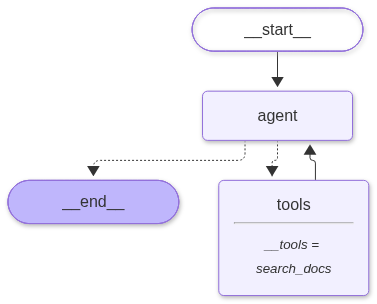

In [7]:
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.errors import GraphRecursionError
from langchain_core.messages import ToolMessage

app = g.compile(checkpointer=InMemorySaver())
cfg = {"configurable": {"thread_id": "acme-1"}, "recursion_limit": 10}


def ask(question: str) -> None:
    """Stream one turn: print each node as it finishes."""
    print(f"› {question}\n")
    try:
        for step in app.stream({"messages": [("user", question)]}, cfg, stream_mode="updates"):
            for node, update in step.items():
                for m in update["messages"]:
                    if getattr(m, "tool_calls", None):
                        print(f" {node:>6} → search_docs{[c['args']['query'] for c in m.tool_calls]}")
                    elif isinstance(m, ToolMessage):
                        print(f" {node:>6} → {m.content.count('[chunk ')} chunks")
                    else:
                        print(f" {node:>6} → {m.content}")
    except GraphRecursionError:
        print(f" stopped: recursion_limit ({cfg['recursion_limit']}) reached, still searching")
    print()


from IPython.display import Image, display

try: # the graph as a picture, drawn by mermaid.ink
    display(Image(app.get_graph().draw_mermaid_png()))
except Exception: # offline: the Mermaid source, to paste into https://mermaid.live
    print(app.get_graph().draw_mermaid())

In [8]:
ask("Thanks!")

› Thanks!



  agent → You're welcome! Let me know if you have any questions about Acme Corp's Q3 2026 or Q2 2026 financial results.



In [9]:
ask("How did Acme's Q3 margin compare to Q2, and why?")

› How did Acme's Q3 margin compare to Q2, and why?



  agent → search_docs['Q3 2026 gross margin operating margin profit margin', 'Q2 2026 gross margin operating margin profit margin']


  tools → 5 chunks
  tools → 5 chunks


  agent → In Q3 2026, Acme's operating margin improved to **21.0%**, compared to **19.4%** in Q2 2026. 

**Reasons for the comparison/improvement:**
* **Lower data-center costs:** Costs per unit of compute decreased due to server utilization improvements and newer facilities with lower power costs coming online.
* **Operating leverage:** The company achieved operating leverage from higher Cloud Services revenue growth.



Same `thread_id`, so the follow-up sees the conversation so far:

In [10]:
ask("And the quarter before?")

› And the quarter before?



  agent → search_docs['Q1 2026 operating margin revenue results']


  tools → 5 chunks


  agent → search_docs['Q1 2026 gross margin operating margin profit margin']


  tools → 5 chunks


  agent → search_docs['Q1 2026 results summary revenue operating income']


  tools → 5 chunks


  agent → In Q1 2026 (the quarter before Q2 2026), Acme's operating margin was **17.8%** (operating income of $655 million on total revenue of $3,702 million).

Comparing Q2 2026 to Q1 2026:
* **Operating Margin:** Q2 operating margin increased to **19.4%** from **17.8%** in Q1.
* **Reasons:** The sequential margin improvement was driven by total revenue growing from $3,702 million in Q1 to $3,911 million in Q2 (led by Cloud Services revenue expanding from $2,010 million to $2,169 million), along with the exit of two low-margin hardware lines in Q1.



It remembered: "the quarter before" was read against the chat so far, so it searched for Q1.
The filing reports no Q1 on its own. A strong model works it out from the nine-month totals
(9M − Q2 − Q3); a weaker one repeats the search, guesses, or runs into `recursion_limit`. Module 3 has
no way to judge its evidence or to stop searching: that is Module 4's job.

In [11]:
state = app.get_state(cfg)
print(f"{len(state.values['messages'])} messages saved on thread acme-1")

15 messages saved on thread acme-1


## 7 · Pause for a human: `interrupt` and resume

`interrupt()` pauses the graph and saves its state. `Command(resume=...)` continues it.
Use it before anything you can't undo: sending, paying, deleting.

In [12]:
from langgraph.types import interrupt, Command


class Draft(TypedDict):
    question: str
    draft: str
    approved: bool


def write_draft(state: Draft):
    out = app.invoke({"messages": [("user", state["question"])]},
                     {"configurable": {"thread_id": "draft-1"}, "recursion_limit": 10})
    return {"draft": out["messages"][-1].content}


def approve(state: Draft):
    ok = interrupt({"question": "Send this answer?", "draft": state["draft"]})
    return {"approved": ok}


h = StateGraph(Draft)
h.add_node("write_draft", write_draft)
h.add_node("approve", approve)
h.add_edge(START, "write_draft")
h.add_edge("write_draft", "approve")
h.add_edge("approve", END)
review = h.compile(checkpointer=InMemorySaver())

hcfg = {"configurable": {"thread_id": "review-1"}}
out = review.invoke({"question": "What was Acme's Q3 revenue?"}, hcfg)
out["__interrupt__"] # the pause and its payload

[Interrupt(value={'question': 'Send this answer?', 'draft': "Acme's total revenue for Q3 2026 was **$4,212 million** (or approximately $4.2 billion).\n\n**Revenue Breakdown by Segment:**\n* **Cloud Services:** $2,398 million\n* **Enterprise Software:** $1,226 million\n* **Devices and Other:** $588 million"}, id='63957d4b51d37ea436e4586c2b35fc2b', response_schema=None)]

In [13]:
review.invoke(Command(resume=True), hcfg) # continue

{'question': "What was Acme's Q3 revenue?",
 'draft': "Acme's total revenue for Q3 2026 was **$4,212 million** (or approximately $4.2 billion).\n\n**Revenue Breakdown by Segment:**\n* **Cloud Services:** $2,398 million\n* **Enterprise Software:** $1,226 million\n* **Devices and Other:** $588 million",
 'approved': True}

## 8 · The shortcut: `create_agent`

Everything above, the agent node, the tools node, the conditional edge and the loop, in one call.
Start with it; drop to `StateGraph` when you need a custom flow, like Module 4's grade and retry.

In [14]:
from langchain.agents import create_agent

agent = create_agent(
    model=init_chat_model(CHAT_MODEL, **CHAT_KWARGS),
    tools=[search_docs],
    system_prompt="You answer questions about Acme.",
)

out = agent.invoke({"messages": [
    {"role": "user", "content": "Q3 revenue?"}]})
out["messages"][-1].content

'For **Q3 2026** (ended September 30, 2026), Acme reported total revenue of **$4,212 million** ($4.212 billion), compared to **$3,684 million** in Q3 2025.\n\n### Breakdown by Segment (Q3 2026):\n* **Cloud Services:** $2,398 million\n* **Enterprise Software:** $1,226 million\n* **Devices and Other:** $588 million'

## Checkpoint · Module 3 decides to search, but trusts what it finds

| ✓ What Module 3 can do | ✗ What still breaks |
|---|---|
| Skips search on small talk | Uses whatever chunks come back → Ch 4 |
| Plans two searches for a two-part question | No second try when results are weak → Ch 4 |
| Remembers the chat with a checkpointer + `thread_id` | Can't say "not in the documents" → Ch 4 |
| | Runs only in a notebook → Ch 5 |

The same graph lives in `agents/langgraph_agent.py`, which `module_6_compare_them_all.ipynb` uses.
Next: `module_4_search_with_judgment.ipynb`.